# A/B Testing Analysis

## Project Goal

The goal of this project is to analyze the results of A/B tests with statistical methods in Python and to visualize the key conversion metrics. It was completed as an assignment of the Mate Academy Data Analytics course. In the course, statistical significance was checked with online calculators; here the calculation is automated with a Python script.

## Scope

- **Tests:** 4 A/B tests, each with a control group (group 1) and a treatment group (group 2). Each group contains about 45K, 51K, 70K and 105K sessions in tests 1–4, and control and treatment are nearly equal in size.
- **Metrics:** 4 conversion metrics, each calculated per session: `add_payment_info`, `add_shipping_info`, `begin_checkout` and `new account`.
- **Method:** a two-sided two-proportion Z-test with a significance level of 0.05. The calculation is written as a function that loops over tests and over a list of metrics, so more metrics can be added without changing the logic.
- **Output:** a CSV file with the results and an interactive Tableau dashboard with a test filter.

The workflow consists of the following stages:

1. Extract and preprocess data from BigQuery.
2. Calculate statistical significance using a two-proportion Z-test.
3. Export results to CSV.
4. Visualize findings in Tableau Public.
5. Interpret the results and give recommendations.

## Key results

- **Test 1 is the only test with statistically significant improvements:** `add_payment_info` +12.5%, `add_shipping_info` +6.6% and `begin_checkout` +6.7% (relative change in conversion).
- **Tests 3 and 4 show significant declines** in some metrics (begin_checkout in both, new account in Test 4), and **Test 2 shows no significant changes.**
- Details, recommendations and limitations are in the Conclusions section at the end of the notebook.


In [ ]:
import pandas as pd
import numpy as np

from scipy import stats
from google.colab import auth
from google.cloud import bigquery

In [ ]:
auth.authenticate_user()

In [ ]:
client = bigquery.Client(project='data-analytics-mate')

## Extracting and Preprocessing Data from BigQuery

The SQL query joins the A/B test assignments with session parameters and aggregates sessions and events by date, country, device, continent, channel, test and test group. The BigQuery dataset is private to course participants, so the notebook cannot be re-run outside the course; the resulting CSV file is linked below.


In [ ]:
query = """
WITH session_info AS (
  SELECT s.date,
        s. ga_session_id,
        sp.country,
        sp.device,
        sp.continent,
        sp.channel,
        ab.test,
        ab.test_group


  FROM `DA.ab_test` AS ab
  JOIN `DA.session` AS s
  ON s.ga_session_id = ab.ga_session_id
  JOIN `DA.session_params` AS sp ON sp.ga_session_id = ab.ga_session_id


), sessions_with_orders AS (


SELECT
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group,
        COUNT(DISTINCT o.ga_session_id) AS sessions_with_orders
FROM `DA.order` AS o
JOIN session_info
ON o.ga_session_id = session_info.ga_session_id
group by
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group
), events AS (
SELECT
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group,
        ep.event_name,
        COUNT(ep.ga_session_id) AS event_cnt
FROM `DA.event_params` AS ep
JOIN session_info ON ep.ga_session_id = session_info.ga_session_id
GROUP BY
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group,
        ep.event_name
), session AS (
SELECT
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group,
        COUNT(DISTINCT session_info.ga_session_id) AS session_cnt
FROM session_info
GROUP BY
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group
), account AS (
SELECT
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group,
        COUNT(DISTINCT acs.ga_session_id) AS new_account_cnt
FROM `DA.account_session` AS acs
JOIN session_info ON session_info.ga_session_id = acs.ga_session_id
GROUP BY
        session_info.date,
        session_info.country,
        session_info.device,
        session_info.continent,
        session_info.channel,
        session_info.test,
        session_info.test_group
)
SELECT  sessions_with_orders.date,
        sessions_with_orders.country,
        sessions_with_orders.device,
        sessions_with_orders.continent,
        sessions_with_orders.channel,
        sessions_with_orders.test,
        sessions_with_orders.test_group,
        'sessions with orders' as event_name,
        sessions_with_orders.sessions_with_orders as value
FROM sessions_with_orders
UNION ALL
SELECT  events.date,
        events.country,
        events.device,
        events.continent,
        events.channel,
        events.test,
        events.test_group,
        event_name,
        events.event_cnt as value
FROM events
UNION ALL
SELECT  session.date,
        session.country,
        session.device,
        session.continent,
        session.channel,
        session.test,
        session.test_group,
        'session' as event_name,
        session.session_cnt as value
FROM session
UNION ALL
SELECT  account.date,
        account.country,
        account.device,
        account.continent,
        account.channel,
        account.test,
        account.test_group,
        'new account' as event_name,
        account.new_account_cnt as value
FROM account

"""

In [ ]:
query_job = client.query(query)
results = query_job.result()

In [ ]:
df = results.to_dataframe()
df.head()

,date,country,device,continent,channel,test,test_group,event_name,value
0,2020-12-08,Palestine,desktop,Asia,Direct,4,2,new account,1
1,2020-12-08,Palestine,desktop,Asia,Direct,3,2,new account,1
2,2020-11-06,Puerto Rico,desktop,Americas,Social Search,2,2,new account,1
3,2020-11-06,Puerto Rico,desktop,Americas,Social Search,1,1,new account,1
4,2020-12-08,Croatia,desktop,Europe,Direct,4,2,new account,1


In [ ]:
unique_event_names = df['event_name'].unique()
unique_event_names

array(['new account', 'sessions with orders', 'user_engagement',
       'first_visit', 'page_view', 'scroll', 'session_start', 'view_item',
       'view_promotion', 'select_promotion', 'begin_checkout',
       'add_shipping_info', 'select_item', 'add_to_cart',
       'view_search_results', 'add_payment_info', 'click', 'session',
       'view_item_list'], dtype=object)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800996 entries, 0 to 800995
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   date        800996 non-null  dbdate
 1   country     800996 non-null  object
 2   device      800996 non-null  object
 3   continent   800996 non-null  object
 4   channel     800996 non-null  object
 5   test        800996 non-null  Int64 
 6   test_group  800996 non-null  Int64 
 7   event_name  800996 non-null  object
 8   value       800996 non-null  Int64 
dtypes: Int64(3), dbdate(1), object(5)
memory usage: 57.3+ MB


In [ ]:
df.describe()

,test,test_group,value
count,800996.0,800996.0,800996.0
mean,2.831191,1.499608,9.475863
std,1.11694,0.5,37.493267
min,1.0,1.0,1.0
25%,2.0,1.0,1.0
50%,3.0,1.0,2.0
75%,4.0,2.0,5.0
max,4.0,2.0,1575.0


## Statistical Significance Calculation

For calculating statistical significance, a two-proportion Z-test is used. In every test, the control group (group 1) is compared with the treatment group (group 2).

For every test and metric:
- The conversion rate (events / sessions) is calculated in each group
- The relative change is calculated: (treatment − control) / control
- The standard error is estimated and the Z-statistic is computed (two-sided test)
- The p-value is obtained

If p-value < 0.05, the difference is considered statistically significant.

The function takes a list of metrics and loops over them, so new metrics can be added without changing the calculation logic.


In [ ]:

from statsmodels.stats.proportion import proportions_ztest

# function for statistical significance calculation
def calculate_ab_results(df, group_by_col='test', metrics=None, control_group=1, treatment_group=2, alpha=0.05):
  """
  Calculates the statistical significance of A/B test results.

  Parameters:
  - df (pd.DataFrame): initial DataFrame.
  - group_by_col (str or list): aggregation dimension (like 'test', 'country', etc.)
  - control_group: control group in 'test_group' column
  - treatment_group: test group in 'test_group' columnt
  - alpha (float): significance level (0.05 by default)
  """
  if metrics is None:
    metrics = ['add_payment_info', 'add_shipping_info', 'begin_checkout', 'new account']

  filter_metrics = list(metrics)
  if 'session' not in filter_metrics:
    filter_metrics.append('session')

  filtered_df = df[df['event_name'].isin(filter_metrics)]


# aggregating data by aggregation dimension, test group and event_name
  agg_df = filtered_df.groupby([group_by_col, 'test_group', 'event_name'])['value'].sum().reset_index()

# separating events
  sessions =  agg_df[agg_df['event_name'] == 'session'].copy()
  sessions = sessions.rename(columns={'value': 'denominator_value'})
  sessions = sessions.drop(columns=['event_name'])

  events = agg_df[agg_df['event_name']!='session'].copy()
  events = events.rename(columns={'value': 'numerator_value'})

  # merging numerators and denominators
  merged = pd.merge(events, sessions, on=[group_by_col, 'test_group'], how='left')

  # transforming table to separate data for group 1 and group 2 into separate columns
  pivot_df = merged.pivot(index=[group_by_col, 'event_name'], columns='test_group')
  pivot_df.columns = [f'{col[0]}_{col[1]}' for col in pivot_df.columns]
  pivot_df = pivot_df.reset_index()

  # constructing a resulting dataframe
  result = pd.DataFrame()

  result[group_by_col] = pivot_df[group_by_col]
  result['metric'] = pivot_df['event_name']
  result['numerator_event'] = pivot_df['event_name']
  result['denominator_event'] = 'session'

  num_ctrl_col = f'numerator_value_{control_group}'
  den_ctrl_col = f'denominator_value_{control_group}'
  result['numerator_control'] = pivot_df[num_ctrl_col].fillna(0)
  result['denominator_control'] = pivot_df[den_ctrl_col].fillna(0)
  result['conversion_rate_control'] = result['numerator_control'] / result['denominator_control']

  num_trt_col = f'numerator_value_{treatment_group}'
  den_trt_col = f'denominator_value_{treatment_group}'
  result['numerator_treatment'] = pivot_df[num_trt_col].fillna(0)
  result['denominator_treatment'] = pivot_df[den_trt_col].fillna(0)
  result['conversion_rate_treatment'] = result['numerator_treatment'] / result['denominator_treatment']

  result['metric_change'] = ((result['conversion_rate_treatment'] - result['conversion_rate_control']) / result['conversion_rate_control']) * 100

  z_stats = []
  p_values = []

  for idx, row in result.iterrows():
    counts = np.array([row['numerator_treatment'], row['numerator_control']])
    nobs = np.array([row['denominator_treatment'], row['denominator_control']])

    if nobs[0] == 0 or nobs[1] == 0:
      z_stats.append(np.nan)
      p_values.append(np.nan)
      continue

    try:
      stat, pval = proportions_ztest(count=counts, nobs=nobs, alternative='two-sided')
      z_stats.append(stat)
      p_values.append(pval)
    except Exception:
      z_stats.append(np.nan)
      p_values.append(np.nan)

  result['z_stat'] = z_stats
  result['p_value'] = p_values

  result['significant'] = result['p_value'] < alpha

  return result

In [ ]:
tests_results = calculate_ab_results(df, group_by_col='test')
tests_results

,test,metric,numerator_event,denominator_event,numerator_control,denominator_control,conversion_rate_control,numerator_treatment,denominator_treatment,conversion_rate_treatment,metric_change,z_stat,p_value,significant
0,1,add_payment_info,add_payment_info,session,1988,45362,0.043825,2229,45193,0.049322,12.542021,3.924884,0.000087,True
1,1,add_shipping_info,add_shipping_info,session,3034,45362,0.066884,3221,45193,0.071272,6.560481,2.603571,0.009226,True
2,1,begin_checkout,begin_checkout,session,3784,45362,0.083418,4021,45193,0.088974,6.660587,2.978783,0.002894,True
3,1,new account,new account,session,3823,45362,0.084278,3681,45193,0.081451,-3.354299,-1.542883,0.122859,False
4,2,add_payment_info,add_payment_info,session,2344,50637,0.04629,2409,50244,0.047946,3.576911,1.240994,0.214608,False
5,2,add_shipping_info,add_shipping_info,session,3480,50637,0.068724,3510,50244,0.069859,1.650995,0.709557,0.477979,False
6,2,begin_checkout,begin_checkout,session,4262,50637,0.084168,4313,50244,0.085841,1.988164,0.952898,0.340642,False
7,2,new account,new account,session,4165,50637,0.082252,4184,50244,0.083274,1.241934,0.588793,0.556000,False
8,3,add_payment_info,add_payment_info,session,3623,70047,0.051722,3697,70439,0.052485,1.47463,0.643172,0.520112,False
9,3,add_shipping_info,add_shipping_info,session,5298,70047,0.075635,5188,70439,0.073652,-2.621211,-1.413727,0.157442,False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

tests_results.to_csv('/content/drive/MyDrive/Mate_HW/projects/portfolio_project_2/ab_tests_results.csv', index=False)

Mounted at /content/drive


The resulting CSV file is used as a secondary data source in Tableau for visualizing statistical significance.

## Dashboard

[Open the interactive dashboard in Tableau Public](https://public.tableau.com/views/ab_17793668147860/ABtest?:language=en-US&:display_count=n&:origin=viz_share_link)

The dashboard shows the four metrics for each test (use the test-number filter) and whether each change is statistically significant.


## Results File

[ab_tests_results.csv](https://drive.google.com/file/d/1ZPjcMYCV88hthLfPwZ287TPInQl223k_/view?usp=sharing)

For every test and metric, the file contains the numerators and denominators, conversion rates of both groups, the relative change (%), the Z-statistic, the p-value and the significance flag.


## Results by Test (dashboard screenshots)

How to read the screenshots: a green check means the change is statistically significant (p < 0.05), and a red cross means it is not. The colour of the numbers shows the direction of a significant change: green is an increase, red is a decrease. "Metric Change" is the relative change in conversion (%) of the treatment group compared with the control group.

### Test 1 Results
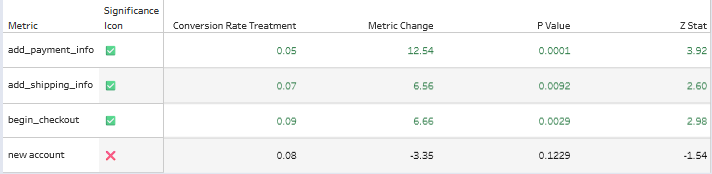
### Test 2 Results
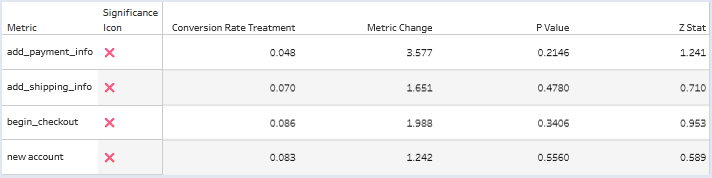
### Test 3 Results
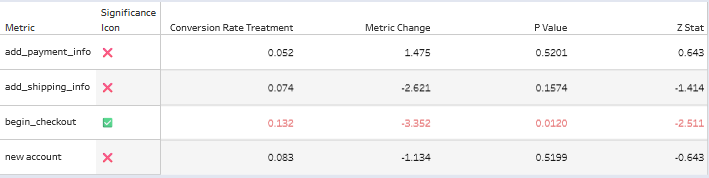
### Test 4 Results
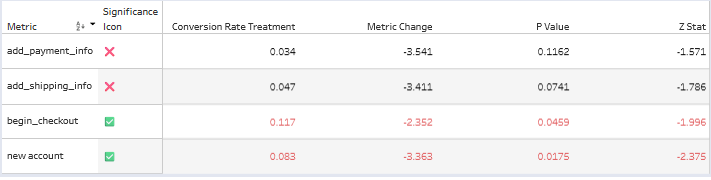

## Conclusions

Statistical significance was calculated for 4 conversion metrics in 4 A/B tests (16 comparisons). The Tableau dashboard allows interactive comparison of all tests and highlights statistically significant changes.

### Results by test

| Test | Result | Details (relative change in conversion, p-value) |
|---|---|---|
| 1 | **Positive** | `add_payment_info` +12.5% (p = 0.0001), `add_shipping_info` +6.6% (p = 0.009), `begin_checkout` +6.7% (p = 0.003). `new account` −3.4%, not significant (p = 0.12). |
| 2 | **No significant changes** | All four metrics changed by +1.2% to +3.6%, all p ≥ 0.21. |
| 3 | **Negative** | `begin_checkout` −3.4% (p = 0.012). The other metrics are not significant (from −2.6% to +1.5%). |
| 4 | **Negative** | `begin_checkout` −2.4% (p = 0.046) and `new account` −3.4% (p = 0.018). `add_payment_info` and `add_shipping_info` are also down by about 3.5%, but not significantly (p = 0.12 and 0.07). |

### Recommendations

- Test 1 is the best candidate for rollout. In the test version, three metrics showed the statistically significant improvement (payment info, shipping info and checkout start), which is a consistent signal. Before a full rollout, it's best to check the effect on completed orders and monitor new account registrations, which dropped by 3.4% (not significant).
- Test 2 is inconclusive. There is no evidence of an effect. The conclusion for this case is either to run the test longer with more traffic or drop the idea.
- Tests 3 and 4 should not be rolled out. Both show declines in some metrics (`begin_checkout` in both, `new_account` in Test 4), and in Test 4 all four metrics moved in the negative direction (two of them significantly). The possible cause should be investigated, and if the idea is still valuable, the variant should be adjusted and tested again.

### Limitations

- The 16 comparisons were made at a significance level of 0.05 without adjustment, so even if there were no real effects, about one significant result (16 × 0.05 = 0.8) would be expected by chance. With a Bonferroni correction (threshold 0.05 / 16 ≈ 0.003), only two results remain significant: `add_payment_info` and `begin_checkout` in Test 1. The other significant results, including the declines in Tests 3 and 4, are weaker evidence and should be confirmed.
- Changes are reported as relative percentages. In absolute terms they are small, for example +0.55 percentage points for `add_payment_info` in Test 1 (4.38% → 4.93%).
- With 45K–105K sessions per group, a test can reliably detect only relative changes of roughly 3–9% (depending on the metric), so smaller real effects, like those in Test 2, may be missed.
- Completed orders and revenue were not analyzed, so the final business effect of each variant is not measured.
- The dataset does not describe what each variant changed or how long the tests ran, so the results cannot be linked to a specific design change, and seasonal or novelty effects cannot be assessed.
